# 10 · Sessions that never reach the till: cancellations, cancel-and-walk, dead handsets (v1.5)

Everything else assumes a SmartShop session ends at the till barcode, where the check decision is
made. In store, some never get there:

- **Genuine cancellation.** A shopper scans a few items (or most of them), gets an urgent call or
  can't find what they came for, cancels SmartShop and leaves the items. Nothing is lost.
- **Cancel-and-walk.** A shoplifter scans items so the session looks normal, cancels, pays
  nothing, and leaves through the self-scan gates behind a customer who has scanned their receipt
  barcode to open them, which is easier when it is busy. **The whole basket is lost, and no check
  ever sees it.**
- **Dead device.** The store's handset (or the shopper's phone) dies part-way. Today the customer
  has to scan everything again. A handset is the store's equipment, so that is the store's
  failure, not the customer's.

Genuine cancellations and cancel-and-walk can both happen early or late, so timing does not tell
them apart.

**What the store has.** Colleagues carry no device. The SmartShop check device at the SmartShop
checkout logs in and scans the barcode a shopper gets for a check. Customers pick their own
handset from the stand, or use their phone, and start with their Nectar card. (v1.3 assumed a
colleague could get a prompt and that the store hands out handsets; neither is true, so v1.5
replaces both.)

| | Today | v1.5 |
|---|---|---|
| Cancelled with items scanned | The session just ends | **Idea 1:** the handset or app asks the shopper to leave the basket at the SmartShop checkout and shows a cancel barcode, which a colleague scans on the check device. A cancel never finished there is an **unfinished cancel** |
| After unfinished cancels | Nothing | **Idea 2:** the member's next shop that reaches the till gets a full check (after one, or after two in 90 days) |
| Handsets | Customers pick any handset | **A:** replace batteries in handsets that keep dying. **B:** a handset back on the stand only briefly asks the customer to take another |
| Handset or phone dies | Customer rescans everything | **D:** resume on another handset or at a till from the Nectar card |

No published figures exist for these rates, so every one is a stated assumption (in
`policy/exits.py` and `ops/handsets.py`) and nine other worlds vary them. Produced by
`python -m smartshop.reporting.exits`; this notebook reads its outputs.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../models/exits.csv')
hs = pd.read_csv('../models/handsets.csv')
grid = pd.read_csv('../models/handset_screen.csv')
fair = pd.read_csv('../models/exits_fairness.csv')
summ = json.load(open('../models/exits_summary.json'))
print(f"cancel-and-walk today: ${summ['walk_out_loss_today']:,.0f}, "
      f"{summ['walk_out_share_of_all_loss_today']:.0%} of all loss, invisible to checks")

cancel-and-walk today: $5,912, 13% of all loss, invisible to checks


## 1. Dead handsets when customers pick freely

In [2]:
hs[['policy', 'sessions', 'failures', 'failures per 1,000 sessions', 'min', 'max',
    'mean point of failure (share of shop)']].round(2)

,policy,sessions,failures,"failures per 1,000 sessions",min,max,mean point of failure (share of shop)
0,Today: customers pick any handset,20433,125,6.12,0.59,12.53,0.64
1,A: replace batteries that keep dying,20433,9,0.44,0.34,0.88,0.71
2,B: 'take another' if back on the stand only br...,20433,79,3.87,0.39,8.91,0.70
3,A+B,20433,6,0.29,0.34,0.83,0.85


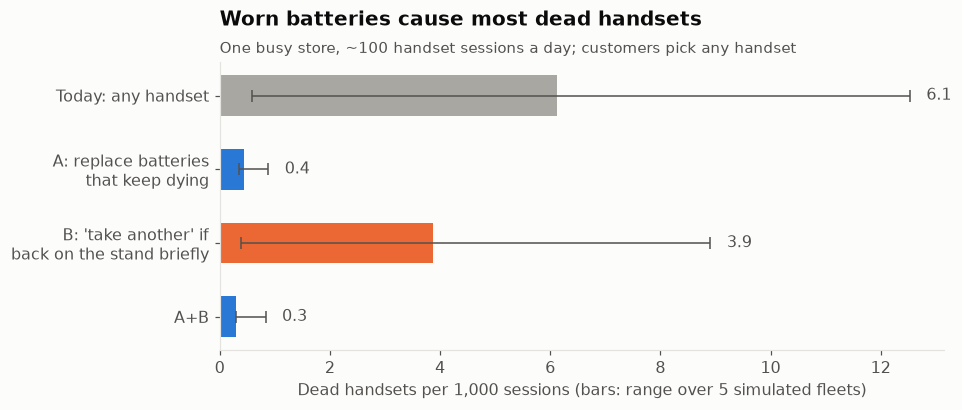

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
labels = ['Today: any handset', 'A: replace batteries\nthat keep dying',
          "B: 'take another' if\nback on the stand briefly", 'A+B']
v = hs['failures per 1,000 sessions']
ax.barh(labels, v, color=[GREY, BLUE, ORANGE, BLUE], height=0.55)
ax.errorbar(v, range(len(v)), xerr=[np.maximum(v - hs['min'], 0), np.maximum(hs['max'] - v, 0)],
            fmt='none', ecolor=TEXT_2, capsize=4, lw=1)
for i, (x, hi) in enumerate(zip(v, hs['max'])):
    ax.text(max(x, hi) + 0.3, i, f'{x:.1f}', va='center', color=TEXT_2)
ax.invert_yaxis()
ax.set_xlabel('Dead handsets per 1,000 sessions (bars: range over 5 simulated fleets)')
ax.grid(axis='y', visible=False)
ax.set_title('Worn batteries cause most dead handsets')
subtitle(ax, 'One busy store, ~100 handset sessions a day; customers pick any handset')
save(fig, '24_dead_handsets')
fig

In [4]:
grid.round(2)  # B: minutes on the stand before a handset stops asking to be left on charge

,minutes,"failures per 1,000 sessions"
0,15.0,3.68
1,30.0,3.56
2,60.0,3.22
3,90.0,3.07
4,120.0,3.30


The handsets show no battery level and customers pick their own, but the store knows which
handset each session used and when it went back on the stand. **Replacing the battery of any
handset that dies twice in 30 days (A) removes most dead handsets**, because a few worn batteries
cause most of them. **B** (a handset back on the stand for less than about 90 minutes asks the
customer to take another) helps on its own but adds little on top of A. When one still dies,
**D** resumes the session instead of making the customer rescan everything.

## 2. Cancellations and cancel-and-walk

In [5]:
base = t[t.world == 'Base assumptions'].set_index('arm')
rows = ['walk-out attempts', 'walk-outs', 'walk-out loss', 'genuine cancellations with items',
        'genuine cancels finished at the SmartShop point', 'colleague hours finishing cancels',
        'unfinished cancels', 'unfinished cancels that were walk-outs',
        'full checks from unfinished cancels', 'of which honest shoppers',
        'honest members checked this way', 'recovered by these checks',
        'colleague hours on these checks', 'dead handsets', 'customer hours lost to dead devices',
        'colleague hours on dead devices']
base[rows].T.round(1)

arm,Today,1: finish cancels at the SmartShop point,1+2: full check after an unfinished cancel,1+2: full check after two in 90 days
walk-out attempts,165.2,165.2,165.2,165.2
walk-outs,134.6,134.6,134.6,134.6
walk-out loss,5912.1,5912.1,5912.1,5912.1
genuine cancellations with items,1146.4,1146.4,1146.4,1146.4
genuine cancels finished at the SmartShop point,0.0,806.0,806.0,806.0
colleague hours finishing cancels,0.0,13.4,13.4,13.4
unfinished cancels,NaN,478.1,478.1,478.1
unfinished cancels that were walk-outs,NaN,137.6,137.6,137.6
full checks from unfinished cancels,0.0,0.0,441.6,72.2
of which honest shoppers,0.0,0.0,374.3,49.2


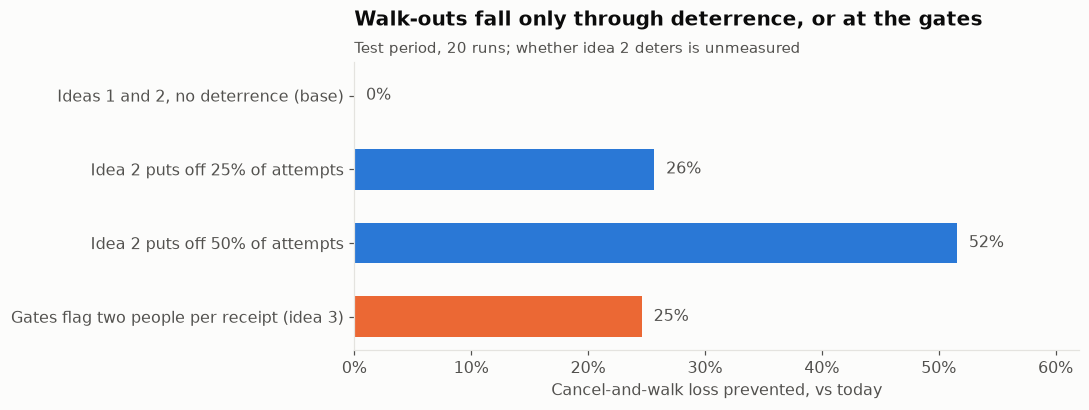

In [6]:
today_base = t[(t.world == 'Base assumptions') & (t.arm == 'Today')]['walk-out loss'].iloc[0]
two = '1+2: full check after two in 90 days'
cases = [
    ('Ideas 1 and 2, no deterrence (base)', 'Base assumptions', two),
    ('Idea 2 puts off 25% of attempts', 'Idea 2 puts off 25% of walk-outs', two),
    ('Idea 2 puts off 50% of attempts', 'Idea 2 puts off 50% of walk-outs', two),
    ('Gates flag two people per receipt (idea 3)', 'Gates flag two people per receipt (idea 3)', 'Today'),
]
v = [t[(t.world == w) & (t.arm == a)]['walk-out loss'].iloc[0] / today_base - 1 for _, w, a in cases]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.barh([c[0] for c in cases], [-x for x in v], color=[GREY, BLUE, BLUE, ORANGE], height=0.55)
for i, x in enumerate(v):
    ax.text(-x + 0.01, i, f'{abs(x):.0%}', va='center', color=TEXT_2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(0, 0.62)
ax.set_xlabel('Cancel-and-walk loss prevented, vs today')
ax.grid(axis='y', visible=False)
ax.set_title('Walk-outs fall only through deterrence, or at the gates')
subtitle(ax, 'Test period, 20 runs; whether idea 2 deters is unmeasured')
save(fig, '25_cancel_and_walk')
fig

**Reading it.**

- **Nothing at the moment of cancelling stops a walk-out** once colleagues get no prompt: in the
  base world every arm loses the same. Gates that flag two people per receipt scan (idea 3,
  hardware) cut it by about a quarter whatever else is done.
- **Idea 1 still earns its place.** About 70% of genuine cancellers (an assumption) leave the
  basket at the point and are helped, and **cancel-and-walk becomes countable**: about 3 in 10
  unfinished cancels are walk-outs, a loss nobody can see today.
- **Idea 2, one strike, is too blunt**: most of those full checks land on honest shoppers who
  forgot to hand the basket back (about 15% of honest members over the period).
- **Idea 2, two in 90 days, is the rule to use**: about 2% of honest members, and it recovers
  about \$154 per colleague hour from the members it does check, about twice the targeted
  policy's rate.
- **Whether idea 2 deters walk-outs is the open question.** If it puts off a quarter of attempts,
  cancel-and-walk falls by about a quarter; if half, by half. A trial should measure it.

## 3. Fairness of idea 2

In [7]:
fair.round(3)

,attribute,lowest,highest,ratio,rule
0,app or handset,0.113,0.121,0.935,1+2: full check after an unfinished cancel
1,age_group,0.166,0.201,0.827,1+2: full check after an unfinished cancel
2,household_size,0.177,0.205,0.861,1+2: full check after an unfinished cancel
3,income_level,0.159,0.228,0.699,1+2: full check after an unfinished cancel
4,app or handset,0.009,0.010,0.936,1+2: full check after two in 90 days
5,age_group,0.011,0.021,0.530,1+2: full check after two in 90 days
6,household_size,0.015,0.021,0.704,1+2: full check after two in 90 days
7,income_level,0.013,0.031,0.436,1+2: full check after two in 90 days


Under the two-in-90-days rule only 1–3% of honest members in any group are checked this way, so a
handful of members moves the group ratios a lot: too few to read as a gap, and worth monitoring in
a trial. Cancelling is never used as a risk-model feature, and a device failure is never a signal.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Cancel-and-walk is about an eighth of all loss and invisible to checks and to the loss estimate | Count unfinished cancels next to the weighted loss estimate |
| 2 | Without a colleague device, nothing at the moment of cancelling stops a walk-out; finishing cancels at the SmartShop point helps genuine shoppers and makes walk-outs countable (3 in 10 unfinished cancels) | **v1.5 idea 1** |
| 3 | A full check after one unfinished cancel mostly checks honest shoppers; after two in 90 days it reaches about 2% of honest members and recovers about \$154 per colleague hour | **v1.5 idea 2: two in 90 days** |
| 4 | Walk-outs fall only if idea 2 deters them (unmeasured); gates that allow one person per receipt cut them by a quarter regardless | Measure deterrence in a trial; recommend the gates |
| 5 | Replacing batteries that keep dying cuts dead handsets by about 93%, from the handset log alone; the "take another" screen adds little | **A first**; resume (D) for the rest |